# P17 – Is This Asteroid a Threat?
**Name:** KHUSHI NARSIDANI
**Roll No.:** C28
**Enrollment No.:** 24004501210223
**Division:** D

**Problem:** Predict whether an asteroid is hazardous from its estimated diameter, relative velocity, miss distance, absolute magnitude and orbital elements.
**Dataset:** https://www.kaggle.com/datasets/shrutimehta/nasa-asteroids-classification
**Target (Y):** Hazardous (True/False)
**Model:** Support Vector Machine (SVM)
**Main metric:** Recall for hazardous asteroids

## Step 1: Create your notebook and load the libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay)
from sklearn.svm import SVC
import warnings; warnings.filterwarnings("ignore")
print("All libraries loaded!")

All libraries loaded!


## Step 2: Load your dataset


In [2]:
df = pd.read_csv("nasa.csv")
print(df.shape)      # (rows, columns)
df.head()

(4687, 40)


,Neo Reference ID,Name,Absolute Magnitude,Est Dia in KM(min),Est Dia in KM(max),Est Dia in M(min),Est Dia in M(max),Est Dia in Miles(min),Est Dia in Miles(max),Est Dia in Feet(min),...,Asc Node Longitude,Orbital Period,Perihelion Distance,Perihelion Arg,Aphelion Dist,Perihelion Time,Mean Anomaly,Mean Motion,Equinox,Hazardous
0,3703080,3703080,21.6,0.127220,0.284472,127.219878,284.472297,0.079051,0.176763,417.388066,...,314.373913,609.599786,0.808259,57.257470,2.005764,2458161.642,264.837533,0.590551,J2000,True
1,3723955,3723955,21.3,0.146068,0.326618,146.067964,326.617897,0.090762,0.202951,479.225620,...,136.717242,425.869294,0.718200,313.091975,1.497352,2457794.969,173.741112,0.845330,J2000,False
2,2446862,2446862,20.3,0.231502,0.517654,231.502122,517.654482,0.143849,0.321655,759.521423,...,259.475979,643.580228,0.950791,248.415038,1.966857,2458120.468,292.893654,0.559371,J2000,True
3,3092506,3092506,27.4,0.008801,0.019681,8.801465,19.680675,0.005469,0.012229,28.876199,...,57.173266,514.082140,0.983902,18.707701,1.527904,2457902.337,68.741007,0.700277,J2000,False
4,3514799,3514799,21.6,0.127220,0.284472,127.219878,284.472297,0.079051,0.176763,417.388066,...,84.629307,495.597821,0.967687,158.263596,1.483543,2457814.455,135.142133,0.726395,J2000,True


## Step 3: Understand the data


In [3]:
df.info()                   # column names, types, non-null counts
df.describe()               # min, max, mean of number columns
print(df.isnull().sum())    # missing values in each column
print("Duplicates:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4687 entries, 0 to 4686
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Neo Reference ID              4687 non-null   int64  
 1   Name                          4687 non-null   int64  
 2   Absolute Magnitude            4687 non-null   float64
 3   Est Dia in KM(min)            4687 non-null   float64
 4   Est Dia in KM(max)            4687 non-null   float64
 5   Est Dia in M(min)             4687 non-null   float64
 6   Est Dia in M(max)             4687 non-null   float64
 7   Est Dia in Miles(min)         4687 non-null   float64
 8   Est Dia in Miles(max)         4687 non-null   float64
 9   Est Dia in Feet(min)          4687 non-null   float64
 10  Est Dia in Feet(max)          4687 non-null   float64
 11  Close Approach Date           4687 non-null   str    
 12  Epoch Date Close Approach     4687 non-null   float64
 13  Relative Veloc

## Step 4: Prepare the target column (Y)


In [4]:
TARGET = "Hazardous"
print(df[TARGET].value_counts())                  # how many rows in each class
print(df[TARGET].value_counts(normalize=True))    # same, as percentages

Hazardous
False    3932
True      755
Name: count, dtype: int64
Hazardous
False    0.838916
True     0.161084
Name: proportion, dtype: float64


✍️ **Write here:** Classes of the target and their counts. Is it balanced or imbalanced?

_(double-click this cell and write your answer)_

## Step 5: Clean the data


In [5]:
df = df.drop_duplicates()

# Drop ID / name / leaking columns (write the real column names from your data)
# df = df.drop(columns=["id_column", "name_column"])

for col in df.columns:
    if col == TARGET: continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())     # number column -> median
    else:
        df[col] = df[col].fillna(df[col].mode()[0])    # text column -> most common value
df = df.dropna(subset=[TARGET])

print(df.isnull().sum().sum(), "missing values left")
print(df.shape)

0 missing values left
(4687, 40)


## Step 6: Explore the data with charts (EDA)


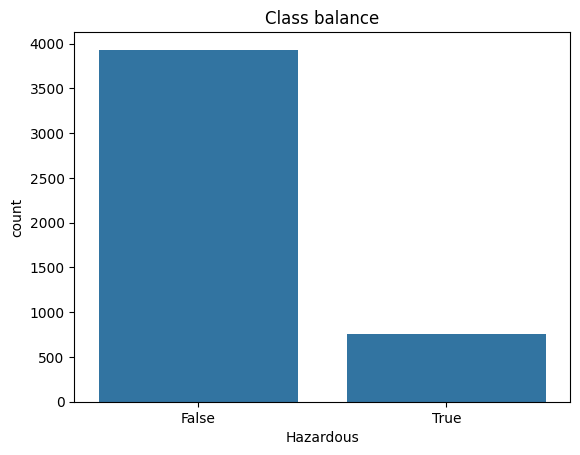

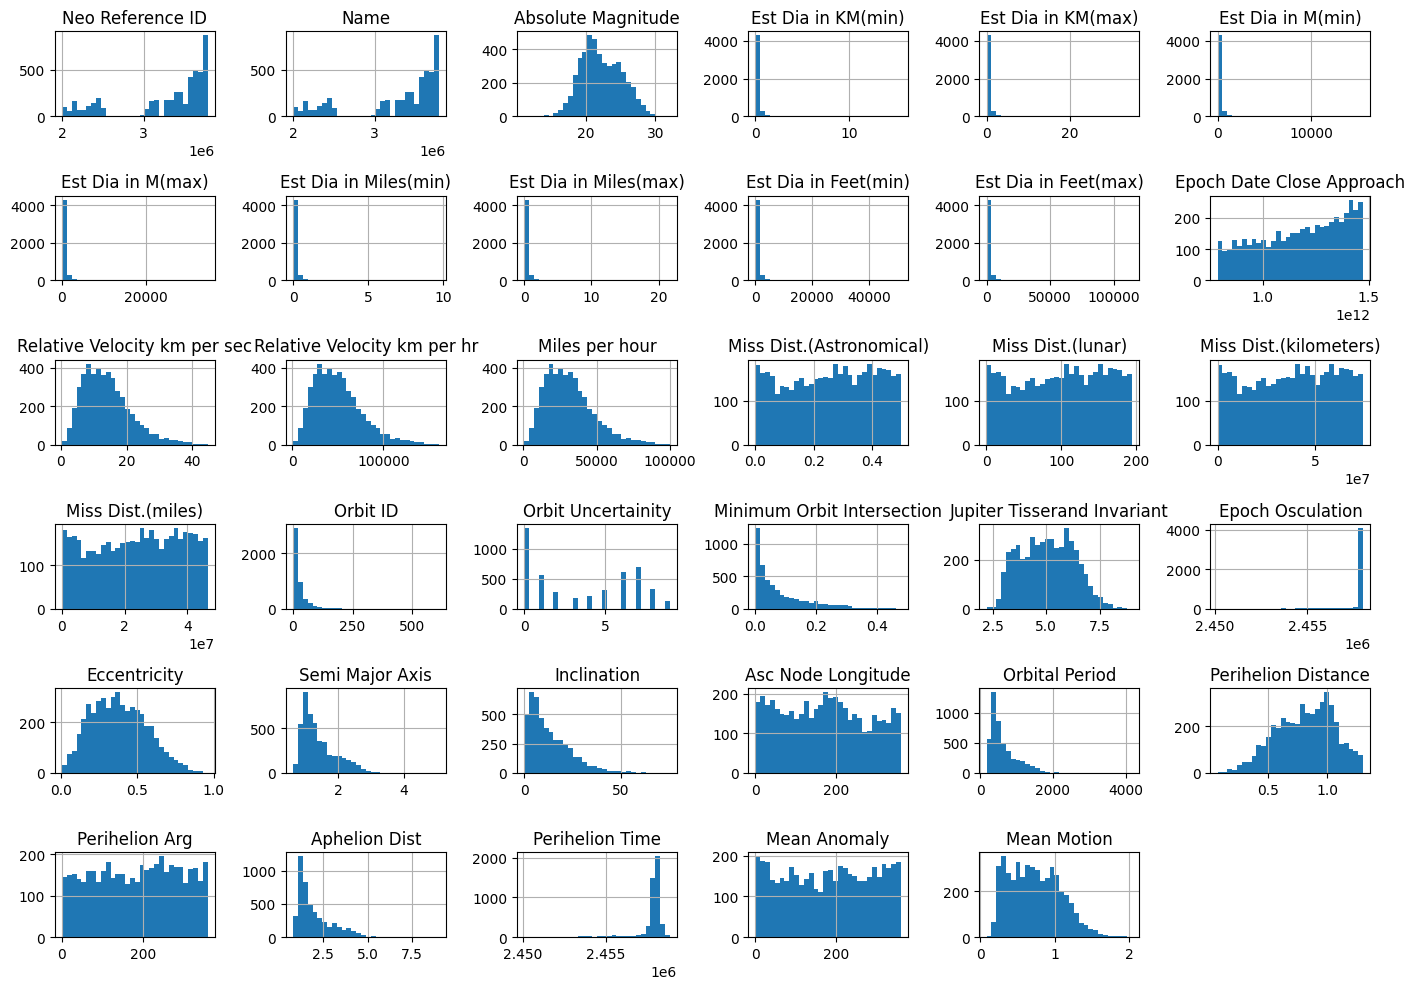

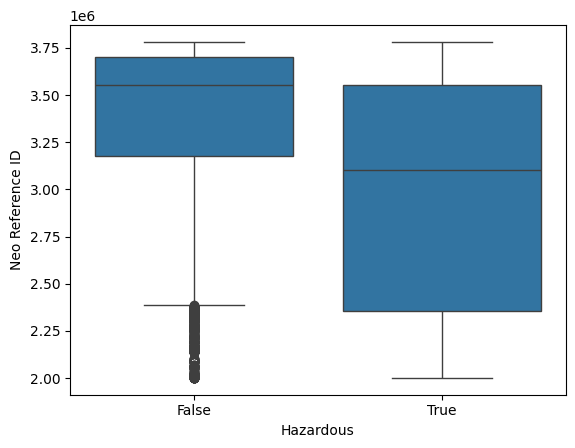

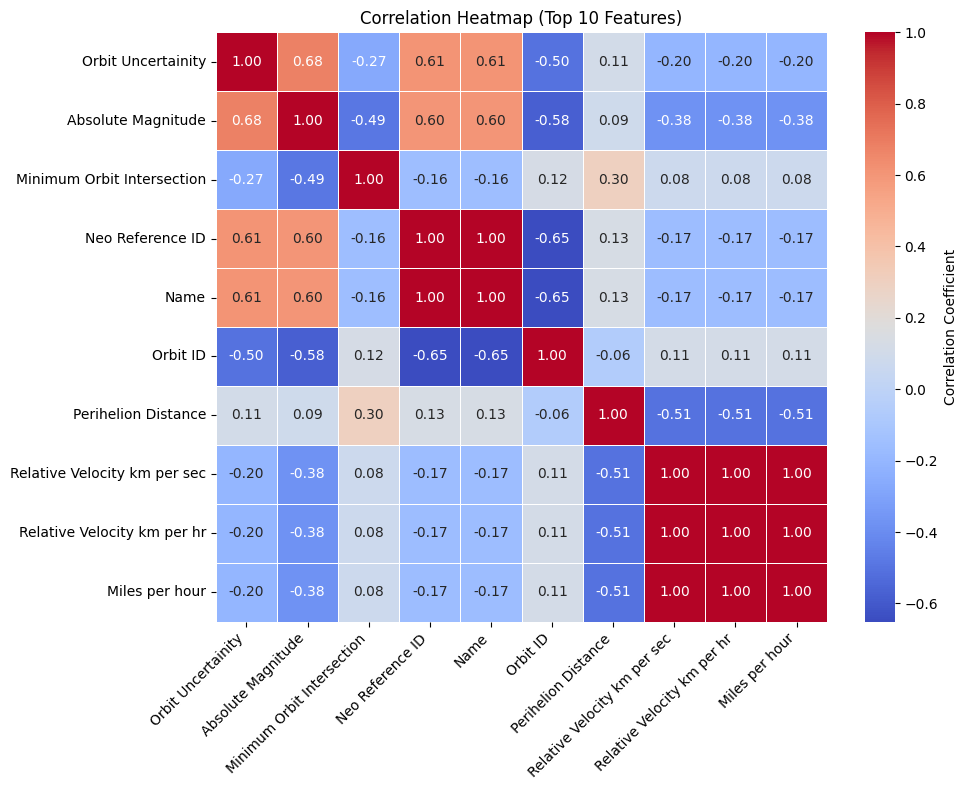

In [12]:
sns.countplot(x=df[TARGET])
plt.title("Class balance")
plt.show()

num_cols = df.select_dtypes(include="number").columns
df[num_cols].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

# Box plot of one important numeric column by class
sns.boxplot(x=df[TARGET], y=df[num_cols[0]])
plt.show()

plt.figure(figsize=(10, 8))

# Select only the top 10 features most correlated with the target to avoid clutter
top_corr_cols = (
    df[num_cols]
    .corrwith(df[TARGET].astype(float))
    .abs()
    .nlargest(10)
    .index
)
corr_subset = df[top_corr_cols].corr()

# Clean heatmap with only the top 10 features
sns.heatmap(
    corr_subset,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"label": "Correlation Coefficient"},
)

plt.title("Correlation Heatmap (Top 10 Features)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 7: Create a new feature, encode and select features


In [13]:
# 1) NEW FEATURE: create at least one new column that makes sense for your data
#    example: df["new_feature"] = df["column_a"] / (df["column_b"] + 1)
#    (change the column names to real columns from YOUR dataset)

# 2) Separate X (inputs) and y (target)
X = df.drop(columns=[TARGET])
le_y = LabelEncoder()
y = le_y.fit_transform(df[TARGET])
print("Classes:", list(le_y.classes_))     # class 0, class 1, ...

# 3) ENCODING: turn text columns into numbers (one-hot encoding)
X = pd.get_dummies(X, drop_first=True)
print(X.shape)

# 4) FEATURE SELECTION (filter method): keep the most useful columns
from sklearn.feature_selection import SelectKBest, f_classif
k = min(15, X.shape[1])
selector = SelectKBest(f_classif, k=k).fit(X, y)
scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(scores.head(20))
X = X[scores.head(k).index]
feature_names = list(X.columns)
print("Selected:", feature_names)

Classes: [np.False_, np.True_]
(4687, 1267)
Orbit Uncertainity                        567.582046
Absolute Magnitude                        555.284236
Minimum Orbit Intersection                426.791311
Name                                      365.538488
Neo Reference ID                          365.538488
Orbit ID                                  305.367797
Perihelion Distance                       209.791493
Relative Velocity km per sec              179.260399
Relative Velocity km per hr               179.260399
Miles per hour                            179.260399
Eccentricity                              162.826743
Est Dia in KM(max)                         83.623580
Est Dia in M(max)                          83.623580
Est Dia in KM(min)                         83.623580
Est Dia in M(min)                          83.623580
Est Dia in Feet(max)                       83.623580
Est Dia in Feet(min)                       83.623580
Est Dia in Miles(max)                      83.623580
Es

## Step 8: Split into train and test + scale


In [14]:
# If your data has more than 20,000 rows, first take a sample (SVM/KNN are slow on big data):
# df = df.sample(20000, random_state=42)   <- do this BEFORE Step 7 and re-run Step 7

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

# SCALING (must for Support Vector Machine (SVM)). Fit ONLY on train data, then apply to test.
X_train_raw, X_test_raw = X_train.copy(), X_test.copy()   # keep unscaled copy
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

(3749, 15) (938, 15)


## Step 9: Train your model: Support Vector Machine (SVM)


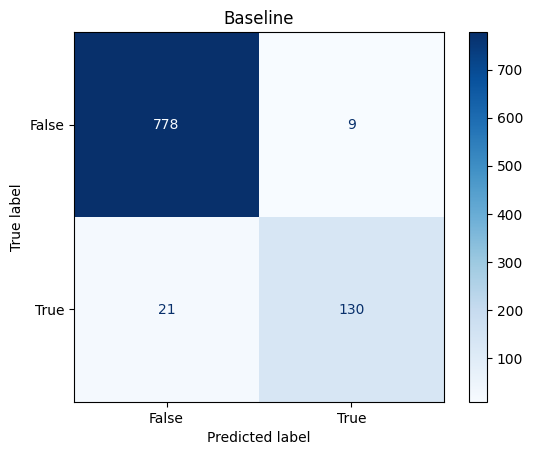

              precision    recall  f1-score   support

       False       0.97      0.99      0.98       787
        True       0.94      0.86      0.90       151

    accuracy                           0.97       938
   macro avg       0.95      0.92      0.94       938
weighted avg       0.97      0.97      0.97       938



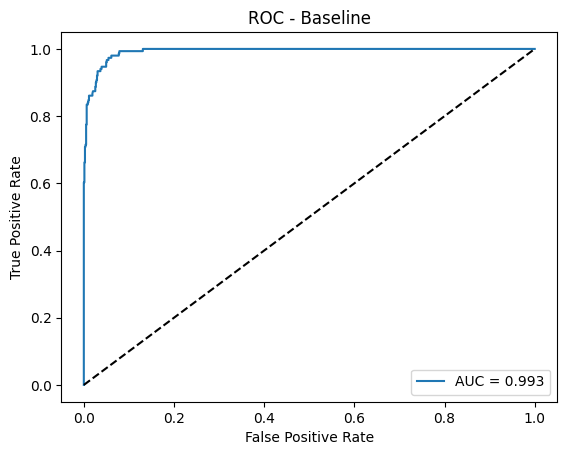

In [15]:
results = []     # every setting you try is stored here

def evaluate(name, model, show=False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp)
    try:
        proba = model.predict_proba(X_test)
        auc = roc_auc_score(y_test, proba[:, 1])
    except Exception:
        auc = None
    row = {"Setting": name,
           "Accuracy": accuracy_score(y_test, y_pred),
           "Precision": precision_score(y_test, y_pred, average="binary", zero_division=0),
           "Recall": recall_score(y_test, y_pred, average="binary", zero_division=0),
           "F1": f1_score(y_test, y_pred, average="binary", zero_division=0),
           "Specificity": spec, "AUC": auc}
    if show:
        ConfusionMatrixDisplay(cm, display_labels=le_y.classes_).plot(cmap="Blues")
        plt.title(name); plt.show()
        print(classification_report(y_test, y_pred, target_names=[str(c) for c in le_y.classes_]))
        
        if auc is not None:
            from sklearn.metrics import roc_curve
            fpr, tpr, thresholds = roc_curve(y_test, proba[:, 1])
            plt.figure()
            plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
            plt.plot([0, 1], [0, 1], 'k--') # Diagonal guessing line
            plt.xlabel("False Positive Rate")
            plt.ylabel("True Positive Rate")
            plt.title("ROC - " + name)
            plt.legend(loc="lower right")
            plt.show()
            
    return row

# BASELINE: your model with default settings
model = SVC(probability=True, random_state=42)
results.append(evaluate("Baseline", model, show=True))

## Step 10: Try different settings (tuning)


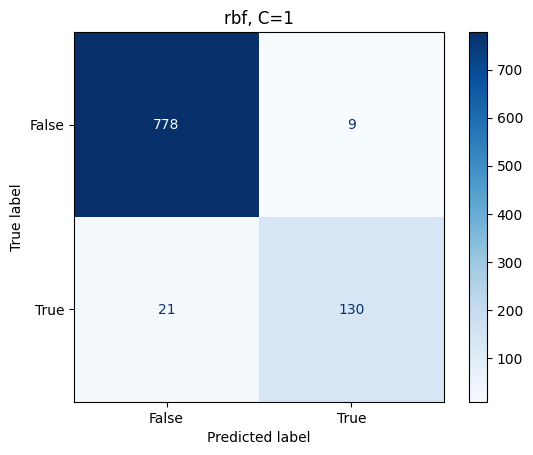

              precision    recall  f1-score   support

       False       0.97      0.99      0.98       787
        True       0.94      0.86      0.90       151

    accuracy                           0.97       938
   macro avg       0.95      0.92      0.94       938
weighted avg       0.97      0.97      0.97       938



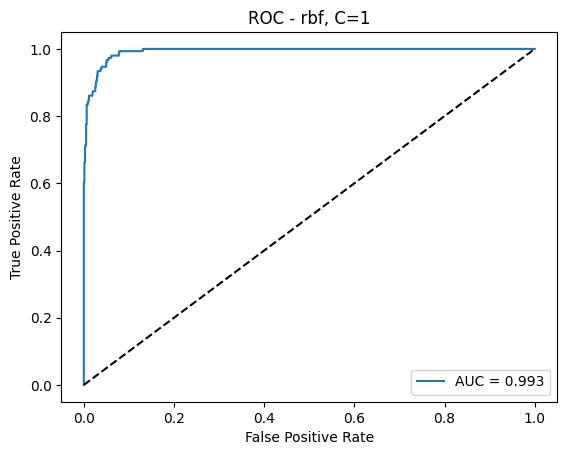

In [16]:
# A) Kernel: linear vs rbf
for kern in ["linear", "rbf"]:
    results.append(evaluate(f"kernel={kern}", SVC(kernel=kern, probability=True, random_state=42)))

# B) C value for the better kernel (change "rbf" if linear was better)
for c in [0.1, 1, 10]:
    results.append(evaluate(f"rbf, C={c}", SVC(kernel="rbf", C=c, probability=True, random_state=42), show=(c == 1)))

✍️ **Write here:** What changed when you changed each setting? Which one was best?

_(double-click this cell and write your answer)_

## Step 11: Compare all settings and pick your final model


,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline,0.968,0.935,0.861,0.897,0.989,0.993
1,kernel=linear,0.953,0.859,0.848,0.853,0.973,0.990
2,kernel=rbf,0.968,0.935,0.861,0.897,0.989,0.993
3,"rbf, C=0.1",0.903,0.885,0.457,0.603,0.989,0.970
4,"rbf, C=1",0.968,0.935,0.861,0.897,0.989,0.993
5,"rbf, C=10",0.977,0.945,0.907,0.926,0.990,0.998


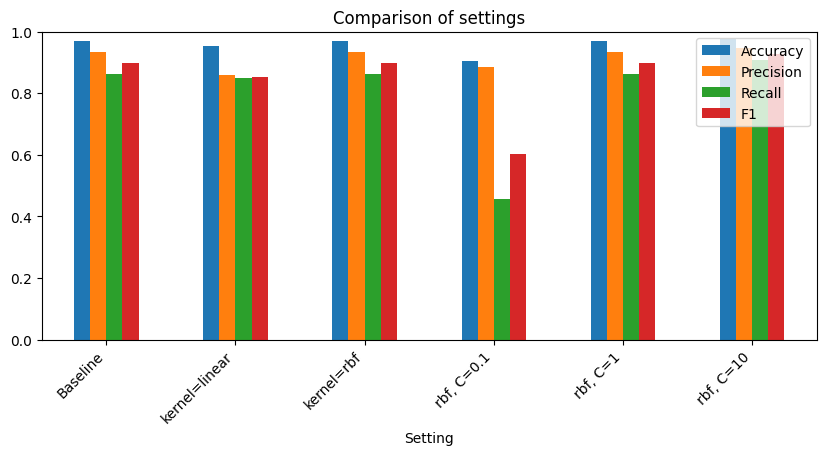

Best setting by Recall: rbf, C=10


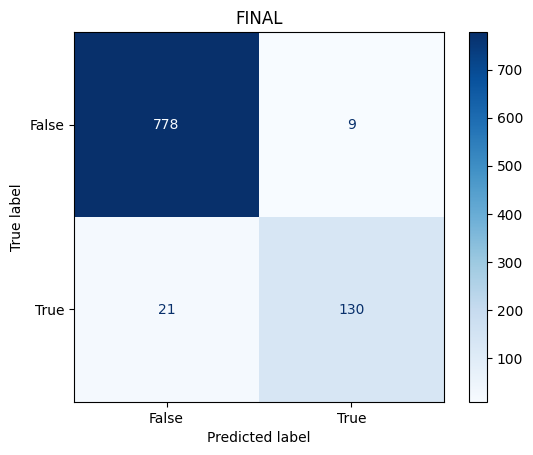

              precision    recall  f1-score   support

       False       0.97      0.99      0.98       787
        True       0.94      0.86      0.90       151

    accuracy                           0.97       938
   macro avg       0.95      0.92      0.94       938
weighted avg       0.97      0.97      0.97       938



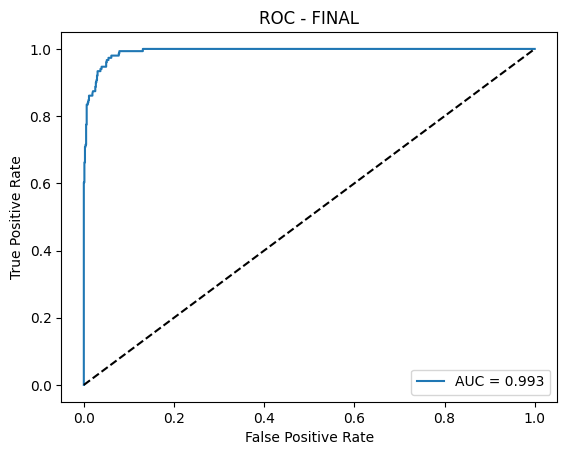

{'Setting': 'FINAL',
 'Accuracy': 0.9680170575692963,
 'Precision': 0.935251798561151,
 'Recall': 0.8609271523178808,
 'F1': 0.896551724137931,
 'Specificity': np.float64(0.98856416772554),
 'AUC': 0.9927337445408417}

In [17]:
res = pd.DataFrame(results).round(3)
display(res)                                    # the comparison table for your report

res.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 4))
plt.title("Comparison of settings"); plt.ylim(0, 1); plt.xticks(rotation=45, ha="right"); plt.show()

best = res.sort_values("Recall", ascending=False).iloc[0]
print("Best setting by Recall:", best["Setting"])

# FINAL MODEL: write the best setting here (example below), then show its full result
final_model = SVC(probability=True, random_state=42)      # <- put your best setting inside ( )
evaluate("FINAL", final_model, show=True)

✍️ **Write here:** Comparison table + bar chart + 3 lines: why you chose this final setting (talk about Recall for hazardous asteroids).

_(double-click this cell and write your answer)_

## Step 12: Predict 3 new inputs


In [18]:
# Start from 3 real rows and change some values to make 3 NEW realistic inputs
new = X.iloc[[0, 1, 2]].copy()
# example: new.iloc[0, 0] = 50       <- change values in your own way and explain why
display(new)
pred = final_model.predict(scaler.transform(new))
print("Predictions:", le_y.inverse_transform(pred))

,Orbit Uncertainity,Absolute Magnitude,Minimum Orbit Intersection,Name,Neo Reference ID,Orbit ID,Perihelion Distance,Relative Velocity km per sec,Relative Velocity km per hr,Miles per hour,Eccentricity,Est Dia in KM(max),Est Dia in M(max),Est Dia in KM(min),Est Dia in M(min)
0,5,21.6,0.025282,3703080,3703080,17,0.808259,6.115834,22017.00380,13680.50994,0.425549,0.284472,284.472297,0.127220,127.219878
1,3,21.3,0.186935,3723955,3723955,21,0.718200,18.113985,65210.34609,40519.17311,0.351674,0.326618,326.617897,0.146068,146.067964
2,0,20.3,0.043058,2446862,2446862,22,0.950791,7.590711,27326.56018,16979.66180,0.348248,0.517654,517.654482,0.231502,231.502122


Predictions: [False False False]
